Parcial Práctico 2 – PDI: Clasificación de poses con una CNN (PyTorch)
Universidad Autónoma de Occidente · Prof. Nicolas Llanos Neuta
Integrantes: Julián Cruz, Sebastián Montaño, Alejandro Quintero.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import hashlib, random
from collections import Counter
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

Mounted at /content/drive


In [ ]:
ROOT = Path('/content/drive/MyDrive/PDI - Parcial2')
CLASSES = ['Belalcazar', 'Discobolo', 'Shakespeare']
EXTS    = {'.jpg', '.jpeg', '.png'}
SEED    = 42
random.seed(SEED); np.random.seed(SEED)

# Carpeta de cada conjunto: train usa el nombre de la clase, val y test llevan prefijo
SPLIT_DIRS = {
    'train': {c: ROOT / c                  for c in CLASSES},
    'val'  : {c: ROOT / f'Validacion-{c}'  for c in CLASSES},
    'test' : {c: ROOT / f'Test-{c}'        for c in CLASSES},
}

# Verifica que existan las 9 carpetas
for s, d in SPLIT_DIRS.items():
    for c, p in d.items():
        assert p.exists(), f"No encuentro {p}"
print("Las 9 carpetas existen.")

Las 9 carpetas existen.


Clase         Train    Val   Test  Total
Belalcazar      128     16     16    160
Discobolo       128     16     16    160
Shakespeare     128     16     16    160
TOTAL           384     48     48    480
Porcentajes reales: train 80.0% | val 10.0% | test 10.0%

Archivos dañados: 0
Archivos ignorados (otra extensión): 0


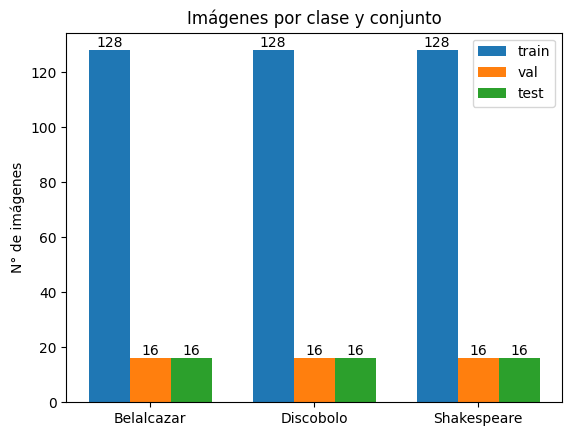

In [ ]:
#conteos por conjunto, balance y archivos dañados

# files[split][clase] = lista de rutas válidas
files, corrupted, ignored = {}, [], []
for s in SPLIT_DIRS:
    files[s] = {}
    for c, folder in SPLIT_DIRS[s].items():
        files[s][c] = []
        for p in sorted(folder.iterdir()):
            if p.suffix.lower() not in EXTS:
                ignored.append(p); continue
            try:
                with Image.open(p) as im: im.verify()   # detecta archivos corruptos
                files[s][c].append(p)
            except Exception as e:
                corrupted.append((p, str(e)))

# Tabla de conteos
print(f"{'Clase':12s} {'Train':>6s} {'Val':>6s} {'Test':>6s} {'Total':>6s}")
for c in CLASSES:
    n = [len(files[s][c]) for s in ('train', 'val', 'test')]
    print(f"{c:12s} {n[0]:6d} {n[1]:6d} {n[2]:6d} {sum(n):6d}")
tot = {s: sum(len(files[s][c]) for c in CLASSES) for s in files}
T = sum(tot.values())
print(f"{'TOTAL':12s} {tot['train']:6d} {tot['val']:6d} {tot['test']:6d} {T:6d}")
print(f"Porcentajes reales: train {tot['train']/T:.1%} | val {tot['val']/T:.1%} | test {tot['test']/T:.1%}")
print("\nArchivos dañados:", len(corrupted)); [print("  ", p, e) for p, e in corrupted]
print("Archivos ignorados (otra extensión):", len(ignored)); [print("  ", p) for p in ignored[:10]]

# Gráfica de barras agrupadas
x = np.arange(len(CLASSES)); w = 0.25
for k, s in enumerate(('train', 'val', 'test')):
    vals = [len(files[s][c]) for c in CLASSES]
    b = plt.bar(x + (k-1)*w, vals, w, label=s)
    plt.bar_label(b)
plt.xticks(x, CLASSES); plt.ylabel('N° de imágenes'); plt.title('Imágenes por clase y conjunto'); plt.legend()
plt.show()

In [ ]:
#duplicados (exactos y casi idénticos, incluyendo espejos)
all_items = [(s, c, p) for s in files for c in CLASSES for p in files[s][c]]

# 1) Duplicados EXACTOS (mismo contenido binario)
md5s = [hashlib.md5(p.read_bytes()).hexdigest() for _, _, p in all_items]
dups = [k for k, v in Counter(md5s).items() if v > 1]
print("Grupos de duplicados exactos:", len(dups))
for k in dups:
    print("  ", [f"{s}/{c}/{p.name}" for (s, c, p), h in zip(all_items, md5s) if h == k])

# 2) Casi duplicados con dHash. Como volteaste fotos a mano, se compara también
#    la versión en espejo, para detectar la misma foto original volteada.
def dhash(im):
    g = np.asarray(im.convert('L').resize((9, 8), Image.LANCZOS), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

H, Hm = [], []
for _, _, p in all_items:
    with Image.open(p) as im:
        im = ImageOps.exif_transpose(im)
        H.append(dhash(im)); Hm.append(dhash(ImageOps.mirror(im)))
H, Hm = np.array(H), np.array(Hm)
d_norm = (H[:, None, :] != H[None, :, :]).sum(-1)
d_mirr = (H[:, None, :] != Hm[None, :, :]).sum(-1)
D = np.minimum(d_norm, d_mirr)               # distancia mínima (normal o espejo)

THR = 5
i, j = np.where(np.triu(D <= THR, k=1))
print(f"\nPares casi duplicados (Hamming <= {THR}): {len(i)}")
cross = [(a, b) for a, b in zip(i, j) if all_items[a][0] != all_items[b][0]]
print(f"  De ellos, entre conjuntos distintos (fuga train/val/test): {len(cross)}")
for a, b in cross[:10]:
    print("  ", f"{all_items[a][0]}/{all_items[a][1]}/{all_items[a][2].name}",
          "<->", f"{all_items[b][0]}/{all_items[b][1]}/{all_items[b][2].name}", f"(d={D[a, b]})")

Grupos de duplicados exactos: 0

Pares casi duplicados (Hamming <= 5): 21
  De ellos, entre conjuntos distintos (fuga train/val/test): 0


Distancia al vecino más cercano en train (menor = más parecido):
  mínima: 12 | mediana: 17


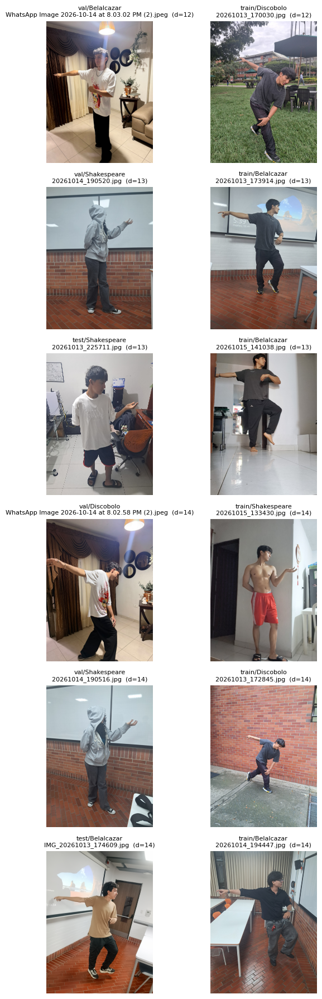

In [ ]:
#revisión visual de fuga (val/test vs. su vecino más parecido en train)
# Para cada foto de val/test se busca la foto de train más parecida.
# Muestra los 6 pares más parecidos para inspeccionarlos con tus propios ojos.
idx_train = [k for k, it in enumerate(all_items) if it[0] == 'train']
idx_eval  = [k for k, it in enumerate(all_items) if it[0] != 'train']

pairs = []
for a in idx_eval:
    b = min(idx_train, key=lambda k: D[a, k])
    pairs.append((D[a, b], a, b))
pairs.sort()

print("Distancia al vecino más cercano en train (menor = más parecido):")
print("  mínima:", pairs[0][0], "| mediana:", int(np.median([p[0] for p in pairs])))

fig, ax = plt.subplots(6, 2, figsize=(7, 18))
for r, (d, a, b) in enumerate(pairs[:6]):
    for col, k in enumerate((a, b)):
        s, c, p = all_items[k]
        ax[r, col].imshow(ImageOps.exif_transpose(Image.open(p)))
        ax[r, col].set_title(f"{s}/{c}\n{p.name}  (d={d})", fontsize=8); ax[r, col].axis('off')
plt.tight_layout(); plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

IMG_SIZE   = 128
BATCH_SIZE = 32
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}   # Belalcazar=0, Discobolo=1, Shakespeare=2

def load_split(split):
    """Lee las imágenes de un conjunto, corrige la orientación EXIF y las redimensiona."""
    imgs, labels, paths = [], [], []
    for c in CLASSES:
        for p in sorted(SPLIT_DIRS[split][c].iterdir()):
            if p.suffix.lower() not in EXTS: continue
            with Image.open(p) as im:
                im = ImageOps.exif_transpose(im).convert('RGB')   # fotos de celular: orientación en metadatos
                imgs.append(im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
            labels.append(CLASS_TO_IDX[c]); paths.append(p)
    return imgs, labels, paths

data = {s: load_split(s) for s in ('train', 'val', 'test')}
for s in data:
    print(s, '->', len(data[s][0]), 'imágenes | por clase:', dict(Counter(data[s][1])))

train -> 384 imágenes | por clase: {0: 128, 1: 128, 2: 128}
val -> 48 imágenes | por clase: {0: 16, 1: 16, 2: 16}
test -> 48 imágenes | por clase: {0: 16, 1: 16, 2: 16}


In [ ]:
# 1) Media y desviación por canal calculadas SOLO con train.
#    Si usáramos val/test, la normalización "vería" datos de evaluación.
to_tensor = T.ToTensor()                                  # PIL -> tensor [0,1], forma (3,H,W)
train_stack = torch.stack([to_tensor(im) for im in data['train'][0]])
MEAN = train_stack.mean(dim=(0, 2, 3)).tolist()
STD  = train_stack.std(dim=(0, 2, 3)).tolist()
print("Media por canal (R,G,B):", [round(m, 4) for m in MEAN])
print("Std   por canal (R,G,B):", [round(s, 4) for s in STD])
del train_stack

# 2) Transform base: tensor + normalización. Se usará en train, val y test.
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

class PoseDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.imgs, self.labels, self.transform = imgs, labels, transform
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return self.transform(self.imgs[i]), self.labels[i]

datasets = {s: PoseDataset(data[s][0], data[s][1], base_tf) for s in data}

g = torch.Generator().manual_seed(SEED)                   # reproducibilidad del barajado
loaders = {
    'train': DataLoader(datasets['train'], batch_size=BATCH_SIZE, shuffle=True,  generator=g),
    'val'  : DataLoader(datasets['val'],   batch_size=BATCH_SIZE, shuffle=False),
    'test' : DataLoader(datasets['test'],  batch_size=BATCH_SIZE, shuffle=False),
}
print({s: len(l) for s, l in loaders.items()}, "lotes por conjunto")

Media por canal (R,G,B): [0.5361, 0.4797, 0.4567]
Std   por canal (R,G,B): [0.2429, 0.2573, 0.256]
{'train': 12, 'val': 2, 'test': 2} lotes por conjunto


#Preparación del dataset

- **Tamaño y balance:** 480 fotos propias, 160 por clase (Belalcazar, Discobolo, Shakespeare). El reparto por carpetas es 128/16/16 por clase, es decir 384/48/48 imágenes, equivalente a 80.0 % / 10.0 % / 10.0 %. Las tres clases están en los tres conjuntos y la distribución es perfectamente balanceada. Se cumple el mínimo de 150 por clase, aunque queda por debajo del ideal de 200+.
- **Limpieza:** 0 archivos dañados, 0 ignorados y 0 duplicados exactos (MD5).
- **Casi duplicados:** el dHash (comparando también la versión en espejo) encontró 21 pares con distancia de Hamming ≤ 5, todos dentro del mismo conjunto y **ninguno entre train, val y test**, por lo que no hay fuga por copias. La foto de val/test más parecida a una de train tiene distancia mínima 12 y mediana 17.
- **Criterio de división:** las fotos de una misma persona y sesión son casi gemelas (ráfagas). Por eso la asignación se hizo por grupos y no foto a foto, para que el accuracy de validación y de test no se inflara por haber visto una foto casi idéntica en train.
- **Preprocesamiento:** se unificó manualmente la orientación lateral de las poses (por eso no se usó flip aleatorio), se corrigió la orientación EXIF, se redimensionó a 128×128 y se normalizó con media [0.5361, 0.4797, 0.4567] y desviación [0.2429, 0.2573, 0.2560], calculadas **solo con train** para que val y test no influyan en la normalización.


Forma del lote: (32, 3, 128, 128) | etiquetas: [1, 0, 1, 0, 2, 1, 2, 1]
Tras normalizar -> media por canal: [0.036, -0.049, -0.052] | std: [1.051, 1.109, 1.077]


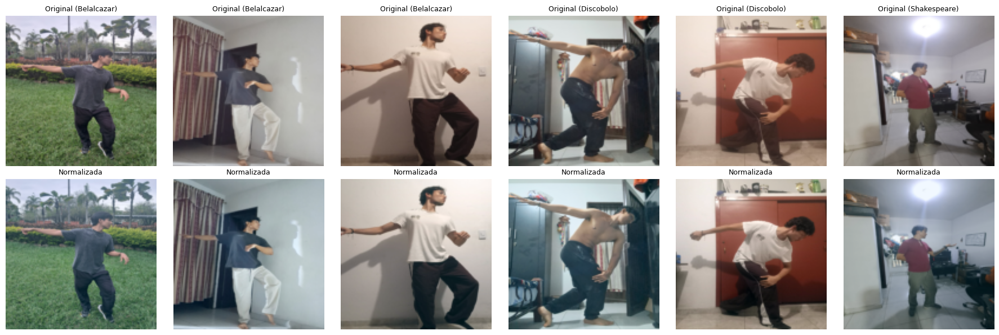

In [ ]:
xb, yb = next(iter(loaders['train']))
print("Forma del lote:", tuple(xb.shape), "| etiquetas:", yb[:8].tolist())
print("Tras normalizar -> media por canal:", [round(v, 3) for v in xb.mean(dim=(0, 2, 3)).tolist()],
      "| std:", [round(v, 3) for v in xb.std(dim=(0, 2, 3)).tolist()])

# Antes (arriba) vs después (abajo, reescalado a [0,1] solo para poder mostrarlo)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for k in range(6):
    orig = data['train'][0][k * 60]                       # una foto cada 60 para ver variedad
    norm = base_tf(orig)
    ax[0, k].imshow(orig); ax[0, k].axis('off')
    ax[0, k].set_title(f"Original ({CLASSES[data['train'][1][k*60]]})", fontsize=9)
    ax[1, k].imshow(((norm - norm.min()) / (norm.max() - norm.min())).permute(1, 2, 0)); ax[1, k].axis('off')
    ax[1, k].set_title("Normalizada", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
#Celda 10
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Dispositivo:", device)

class PoseCNN(nn.Module):
    """
    CNN para clasificar 3 poses (Belalcazar, Discobolo, Shakespeare).
    Entrada: (N, 3, 128, 128)
    3 bloques [Conv 3x3 -> ReLU -> MaxPool 2x2] y luego capas totalmente conectadas.
    p_drop controla el Dropout (0.0 = sin Dropout), para poder comparar en la Etapa 4.
    """
    def __init__(self, num_classes=3, p_drop=0.0, hidden=128):
        super().__init__()
        # Bloque 1: 3 -> 16 canales | 128x128 -> 64x64 tras pool
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        # Bloque 2: 16 -> 32 canales | 64x64 -> 32x32
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        # Bloque 3: 32 -> 64 canales | 32x32 -> 16x16
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(2, 2)

        # Capas completamente conectadas (toma de decisión)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 16 * 16, hidden)
        self.dropout = nn.Dropout(p_drop)
        self.fc2 = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = self.flatten(x)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

Dispositivo: cpu


In [ ]:
model = PoseCNN(num_classes=3, p_drop=0.0).to(device)
print(model)

# Forma de salida con un lote real
xb, yb = next(iter(loaders['train']))
with torch.no_grad():
    out = model(xb.to(device))
print("\nEntrada:", tuple(xb.shape), "-> Salida:", tuple(out.shape))   # debe ser (32, 3)

# Parámetros por capa y total
total = 0
for name, p in model.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):20s} {p.numel():>10,d}")
    total += p.numel()
print(f"{'TOTAL':14s} {'':20s} {total:>10,d}")

# Loss esperada de una red sin entrenar con 3 clases: ln(3) ≈ 1.0986
crit = nn.CrossEntropyLoss()
print("\nLoss inicial:", round(crit(out, yb.to(device)).item(), 4), "| referencia ln(3) = 1.0986")

PoseCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)

Entrada: (32, 3, 128, 128) -> Salida: (32, 3)
conv1.weight   (16, 3, 3, 3)               432
conv1.bias     (16,)                        16
conv2.weight   (32, 16, 3, 3)            4,608
conv2.bias     (32,)                        32
conv3.weight   (64, 32, 3, 3)           18,432
conv3.

#Diseño y entrenamiento

- **Arquitectura final (Modelo E):** 3 capas convolucionales (3→16→32→64 filtros, kernel 3×3, padding 1), cada una con ReLU y MaxPool 2×2 (128→64→32→16), seguidas de 2 capas totalmente conectadas (16384→32→3) con Dropout 0.5 sobre `fc1`. Tiene 548,003 parámetros, frente a 2,121,251 de la versión con `fc1`=128.
- **Por qué así:** el kernel 3×3 es el equilibrio entre detección y costo visto en clase. Las convoluciones apiladas combinan bordes en partes y luego en formas, y el pooling reduce la resolución y el tamaño de `fc1`. La salida son 3 logits porque `CrossEntropyLoss` ya aplica softmax. La profundidad (3 bloques) se eligió por analogía con los notebooks de clase y por el tamaño del dataset, **no se comparó experimentalmente contra otras profundidades**. Lo único decidido con experimentos fue el tamaño de `fc1` (128 → 32).
- **Entrenamiento:** Adam (lr 1e-3), `CrossEntropyLoss`, lotes de 32, y validación en cada época registrando la loss de train y de validación. La loss inicial (1.0943) quedó cerca de ln(3) = 1.0986, lo esperable en una red sin entrenar con 3 clases.

In [ ]:
#12 funciones de entrenamiento y Early Stopping
import copy, time

EPOCHS = 40
LR     = 1e-3

def make_train_loader():
    # Mismo barajado en cada corrida para que A y B sean comparables
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(datasets['train'], batch_size=BATCH_SIZE, shuffle=True, generator=g)

def run_epoch(model, loader, criterion, optimizer=None):
    """Una pasada por el loader. Con optimizer: entrena. Sin optimizer: solo evalúa."""
    training = optimizer is not None
    model.train(training)                       # activa/desactiva Dropout
    loss_sum, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)                      # 1) forward
            loss = criterion(out, y)            # 2) pérdida
            if training:
                optimizer.zero_grad()
                loss.backward()                 # 3) backward (gradientes)
                optimizer.step()                # 4) actualización de pesos
            loss_sum += loss.item() * y.size(0)
            correct  += (out.argmax(1) == y).sum().item()
            n        += y.size(0)
    return loss_sum / n, 100 * correct / n

class EarlyStopping:
    """Detiene el entrenamiento si la loss de validación no mejora en `patience` épocas
    seguidas y guarda los mejores pesos (menor val_loss)."""
    def __init__(self, patience=7, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.best_epoch, self.counter, self.best_state = float('inf'), 0, 0, None
    def step(self, val_loss, model, epoch):
        if val_loss < self.best - self.min_delta:
            self.best, self.best_epoch, self.counter = val_loss, epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
        return self.counter >= self.patience     # True = parar

def train_model(name, p_drop, weight_decay, use_early_stopping, patience=7, hidden=128):
    torch.manual_seed(SEED)
    model = PoseCNN(num_classes=3, p_drop=p_drop, hidden=hidden).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=weight_decay)  # L2 = weight_decay
    train_loader = make_train_loader()
    es = EarlyStopping(patience=patience)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    print(f"=== {name} | Dropout={p_drop} | weight_decay={weight_decay} | EarlyStopping={use_early_stopping} ===")
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, loaders['val'], criterion)           # validación en CADA época
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        stop = es.step(vl, model, epoch)
        print(f"Época {epoch:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:5.1f}% | val loss {vl:.4f} acc {va:5.1f}%"
              + ("  <- mejor val_loss" if es.best_epoch == epoch else ""))
        if use_early_stopping and stop:
            print(f"Early Stopping en la época {epoch}. Mejor época: {es.best_epoch} (val_loss={es.best:.4f})")
            break
    print(f"Tiempo: {time.time() - t0:.0f} s\n")

    if use_early_stopping:
        model.load_state_dict(es.best_state)      # recupera los mejores pesos
    hist['best_epoch'], hist['best_val_loss'] = es.best_epoch, es.best
    return model, hist

In [ ]:
model_A, hist_A = train_model('Modelo A (base)', p_drop=0.0, weight_decay=0.0, use_early_stopping=False)
print("A -> mejor val_loss:", round(hist_A['best_val_loss'], 4), "en la época", hist_A['best_epoch'])

=== Modelo A (base) | Dropout=0.0 | weight_decay=0.0 | EarlyStopping=False ===
Época  1/40 | train loss 1.1409 acc  39.6% | val loss 1.0555 acc  60.4%  <- mejor val_loss
Época  2/40 | train loss 0.8696 acc  67.4% | val loss 0.9080 acc  58.3%  <- mejor val_loss
Época  3/40 | train loss 0.5438 acc  81.5% | val loss 0.6523 acc  70.8%  <- mejor val_loss
Época  4/40 | train loss 0.3411 acc  88.8% | val loss 0.6463 acc  68.8%  <- mejor val_loss
Época  5/40 | train loss 0.2008 acc  93.5% | val loss 0.7560 acc  66.7%
Época  6/40 | train loss 0.0987 acc  96.9% | val loss 0.8651 acc  62.5%
Época  7/40 | train loss 0.0374 acc  99.5% | val loss 0.9639 acc  66.7%
Época  8/40 | train loss 0.0175 acc  99.5% | val loss 1.2292 acc  68.8%
Época  9/40 | train loss 0.0075 acc 100.0% | val loss 1.0784 acc  68.8%
Época 10/40 | train loss 0.0028 acc 100.0% | val loss 1.1662 acc  68.8%
Época 11/40 | train loss 0.0018 acc 100.0% | val loss 1.2253 acc  68.8%
Época 12/40 | train loss 0.0008 acc 100.0% | val loss

In [ ]:
model_B, hist_B = train_model('Modelo B (regularizado)', p_drop=0.5, weight_decay=1e-4,
                              use_early_stopping=True, patience=7)
print("B -> mejor val_loss:", round(hist_B['best_val_loss'], 4), "en la época", hist_B['best_epoch'])

=== Modelo B (regularizado) | Dropout=0.5 | weight_decay=0.0001 | EarlyStopping=True ===
Época  1/40 | train loss 1.1115 acc  43.0% | val loss 1.0309 acc  60.4%  <- mejor val_loss
Época  2/40 | train loss 0.8384 acc  63.3% | val loss 0.7926 acc  70.8%  <- mejor val_loss
Época  3/40 | train loss 0.5828 acc  78.9% | val loss 0.6267 acc  72.9%  <- mejor val_loss
Época  4/40 | train loss 0.3805 acc  87.2% | val loss 0.6215 acc  77.1%  <- mejor val_loss
Época  5/40 | train loss 0.2490 acc  91.9% | val loss 0.7087 acc  68.8%
Época  6/40 | train loss 0.1278 acc  95.8% | val loss 1.0278 acc  60.4%
Época  7/40 | train loss 0.1083 acc  95.8% | val loss 1.1695 acc  64.6%
Época  8/40 | train loss 0.0936 acc  97.4% | val loss 1.2200 acc  58.3%
Época  9/40 | train loss 0.0497 acc  98.2% | val loss 1.2108 acc  64.6%
Época 10/40 | train loss 0.0507 acc  99.0% | val loss 1.0946 acc  72.9%
Época 11/40 | train loss 0.0346 acc  98.4% | val loss 1.0374 acc  68.8%
Early Stopping en la época 11. Mejor época:

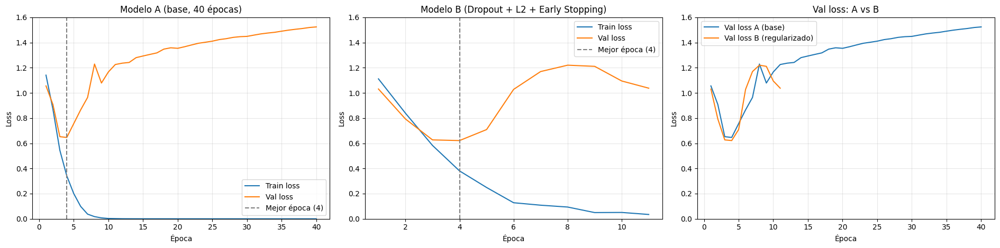

In [ ]:
def plot_losses(ax, h, title):
    ep = range(1, len(h['train_loss']) + 1)
    ax.plot(ep, h['train_loss'], label='Train loss')
    ax.plot(ep, h['val_loss'],   label='Val loss')
    ax.axvline(h['best_epoch'], ls='--', color='gray', label=f"Mejor época ({h['best_epoch']})")
    ax.set_title(title); ax.set_xlabel('Época'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
plot_losses(ax[0], hist_A, 'Modelo A (base, 40 épocas)')
plot_losses(ax[1], hist_B, 'Modelo B (Dropout + L2 + Early Stopping)')
ymax = max(max(hist_A['val_loss']), max(hist_B['val_loss'])) * 1.05
ax[0].set_ylim(0, ymax); ax[1].set_ylim(0, ymax)          # misma escala para comparar

# Comparación directa de la loss de validación
ax[2].plot(range(1, len(hist_A['val_loss']) + 1), hist_A['val_loss'], label='Val loss A (base)')
ax[2].plot(range(1, len(hist_B['val_loss']) + 1), hist_B['val_loss'], label='Val loss B (regularizado)')
ax[2].set_title('Val loss: A vs B'); ax[2].set_xlabel('Época'); ax[2].set_ylabel('Loss')
ax[2].set_ylim(0, ymax); ax[2].legend(); ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
def resumen(name, h):
    b = h['best_epoch'] - 1
    n = len(h['train_loss'])
    print(f"{name}: épocas={n} | mejor época={h['best_epoch']}")
    print(f"   en la mejor época -> train loss {h['train_loss'][b]:.4f} | val loss {h['val_loss'][b]:.4f} "
          f"| val acc {h['val_acc'][b]:.1f}% | brecha val-train {h['val_loss'][b]-h['train_loss'][b]:.4f}")
    print(f"   en la última época -> train loss {h['train_loss'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f} "
          f"| brecha {h['val_loss'][-1]-h['train_loss'][-1]:.4f}")

resumen('Modelo A', hist_A)
resumen('Modelo B', hist_B)

# Comparación en las mismas épocas (5 a 11, las que B alcanzó a correr)
a = np.mean(hist_A['val_loss'][4:11]); b = np.mean(hist_B['val_loss'][4:11])
print(f"\nVal loss promedio, épocas 5-11 -> A: {a:.4f} | B: {b:.4f}")

Modelo A: épocas=40 | mejor época=4
   en la mejor época -> train loss 0.3411 | val loss 0.6463 | val acc 68.8% | brecha val-train 0.3051
   en la última época -> train loss 0.0001 | val loss 1.5238 | brecha 1.5238
Modelo B: épocas=11 | mejor época=4
   en la mejor época -> train loss 0.3805 | val loss 0.6215 | val acc 77.1% | brecha val-train 0.2410
   en la última época -> train loss 0.0346 | val loss 1.0374 | brecha 1.0029

Val loss promedio, épocas 5-11 -> A: 1.0406 | B: 1.0670


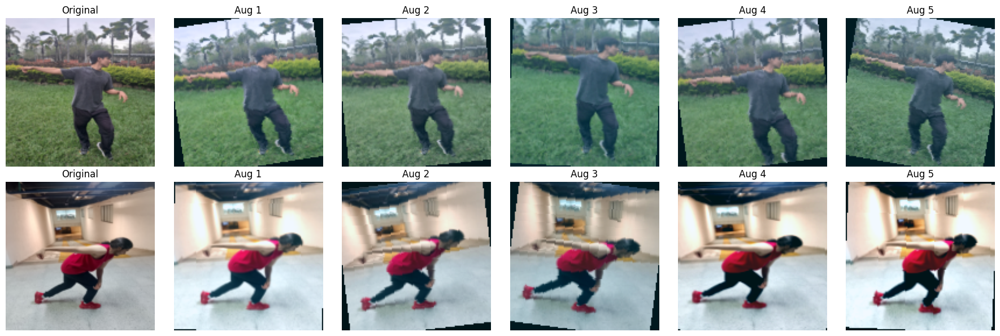

In [ ]:
# Augmentation solo para TRAIN. Val y test siguen con base_tf (sin cambios aleatorios).
# Sin flip horizontal: ya orientaste el dataset a mano.
aug_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),  # recorte/zoom leve
    T.RandomRotation(10),                                               # rotación de ±10°
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),        # luz y color
    T.ToTensor(),
    T.Normalize(MEAN, STD),                                             # misma normalización de train
])
train_ds_aug = PoseDataset(data['train'][0], data['train'][1], aug_tf)

# Muestra cómo se ve una misma foto con 5 augmentations distintas
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for r, k in enumerate((0, 200)):
    ax[r, 0].imshow(data['train'][0][k]); ax[r, 0].set_title('Original'); ax[r, 0].axis('off')
    for c in range(1, 6):
        x, _ = train_ds_aug[k]
        x = (x - x.min()) / (x.max() - x.min())           # solo para poder mostrarla
        ax[r, c].imshow(x.permute(1, 2, 0)); ax[r, c].axis('off'); ax[r, c].set_title(f'Aug {c}')
plt.tight_layout(); plt.show()

In [ ]:
# make_train_loader ahora usa el dataset con augmentation (train_model lo llama por nombre)
def make_train_loader():
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, generator=g)

EPOCHS = 60   # con augmentation la red aprende más lento, necesita más margen
model_C, hist_C = train_model('Modelo C (B + Data Augmentation)', p_drop=0.5, weight_decay=1e-4,
                              use_early_stopping=True, patience=10)
print("C -> mejor val_loss:", round(hist_C['best_val_loss'], 4), "en la época", hist_C['best_epoch'])

=== Modelo C (B + Data Augmentation) | Dropout=0.5 | weight_decay=0.0001 | EarlyStopping=True ===
Época  1/60 | train loss 1.1459 acc  37.2% | val loss 1.0849 acc  43.8%  <- mejor val_loss
Época  2/60 | train loss 1.0321 acc  49.7% | val loss 1.0044 acc  54.2%  <- mejor val_loss
Época  3/60 | train loss 0.9199 acc  57.8% | val loss 0.9218 acc  64.6%  <- mejor val_loss
Época  4/60 | train loss 0.7536 acc  69.5% | val loss 0.9297 acc  54.2%
Época  5/60 | train loss 0.7023 acc  71.6% | val loss 0.7644 acc  66.7%  <- mejor val_loss
Época  6/60 | train loss 0.6135 acc  76.3% | val loss 0.7613 acc  75.0%  <- mejor val_loss
Época  7/60 | train loss 0.6108 acc  76.3% | val loss 0.8505 acc  66.7%
Época  8/60 | train loss 0.4743 acc  81.2% | val loss 0.8108 acc  66.7%
Época  9/60 | train loss 0.4504 acc  84.1% | val loss 0.8901 acc  64.6%
Época 10/60 | train loss 0.3627 acc  88.0% | val loss 0.9320 acc  68.8%
Época 11/60 | train loss 0.3669 acc  87.0% | val loss 0.8772 acc  66.7%
Época 12/60 | t

In [ ]:
# make_train_loader sigue usando train_ds_aug (definido en la Celda 18)
model_D, hist_D = train_model('Modelo D (A + Data Augmentation)', p_drop=0.0, weight_decay=0.0,
                              use_early_stopping=True, patience=10)
print("D -> mejor val_loss:", round(hist_D['best_val_loss'], 4), "en la época", hist_D['best_epoch'])

=== Modelo D (A + Data Augmentation) | Dropout=0.0 | weight_decay=0.0 | EarlyStopping=True ===
Época  1/60 | train loss 1.1368 acc  38.0% | val loss 1.0694 acc  66.7%  <- mejor val_loss
Época  2/60 | train loss 0.9519 acc  61.5% | val loss 1.0244 acc  47.9%  <- mejor val_loss
Época  3/60 | train loss 0.8136 acc  64.8% | val loss 0.7679 acc  75.0%  <- mejor val_loss
Época  4/60 | train loss 0.6226 acc  79.9% | val loss 0.7214 acc  68.8%  <- mejor val_loss
Época  5/60 | train loss 0.5363 acc  77.3% | val loss 0.7758 acc  66.7%
Época  6/60 | train loss 0.4344 acc  83.1% | val loss 0.7114 acc  70.8%  <- mejor val_loss
Época  7/60 | train loss 0.3898 acc  85.4% | val loss 0.8436 acc  68.8%
Época  8/60 | train loss 0.3968 acc  84.4% | val loss 0.7531 acc  64.6%
Época  9/60 | train loss 0.3571 acc  88.3% | val loss 0.6914 acc  75.0%  <- mejor val_loss
Época 10/60 | train loss 0.3180 acc  88.8% | val loss 0.6851 acc  77.1%  <- mejor val_loss
Época 11/60 | train loss 0.2792 acc  90.4% | val los

In [ ]:
#21
EPOCHS = 40
TRAIN_DS = datasets['train']          # sin augmentation
def make_train_loader():
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(TRAIN_DS, batch_size=BATCH_SIZE, shuffle=True, generator=g)

model_E, hist_E = train_model('Modelo E (B con fc1=32)', p_drop=0.5, weight_decay=1e-4,
                              use_early_stopping=True, patience=7, hidden=32)
print("E -> parámetros:", sum(p.numel() for p in model_E.parameters()))
print("E -> mejor val_loss:", round(hist_E['best_val_loss'], 4), "en la época", hist_E['best_epoch'])

=== Modelo E (B con fc1=32) | Dropout=0.5 | weight_decay=0.0001 | EarlyStopping=True ===
Época  1/40 | train loss 1.1072 acc  36.2% | val loss 1.0800 acc  39.6%  <- mejor val_loss
Época  2/40 | train loss 0.9878 acc  53.6% | val loss 0.8910 acc  64.6%  <- mejor val_loss
Época  3/40 | train loss 0.8079 acc  65.4% | val loss 0.7078 acc  75.0%  <- mejor val_loss
Época  4/40 | train loss 0.6050 acc  73.2% | val loss 0.5494 acc  81.2%  <- mejor val_loss
Época  5/40 | train loss 0.4631 acc  81.5% | val loss 0.4742 acc  77.1%  <- mejor val_loss
Época  6/40 | train loss 0.3199 acc  87.0% | val loss 0.4263 acc  83.3%  <- mejor val_loss
Época  7/40 | train loss 0.3129 acc  89.1% | val loss 0.6677 acc  66.7%
Época  8/40 | train loss 0.2331 acc  92.4% | val loss 0.6505 acc  70.8%
Época  9/40 | train loss 0.1954 acc  91.9% | val loss 0.6595 acc  72.9%
Época 10/40 | train loss 0.1982 acc  91.9% | val loss 0.7298 acc  70.8%
Época 11/40 | train loss 0.1675 acc  93.2% | val loss 0.7050 acc  75.0%
Época

In [ ]:
#22
color_tf = T.Compose([
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),   # sin rotación ni recorte
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
TRAIN_DS = PoseDataset(data['train'][0], data['train'][1], color_tf)   # make_train_loader lo toma de aquí
EPOCHS = 60

model_F, hist_F = train_model('Modelo F (B + aug solo color)', p_drop=0.5, weight_decay=1e-4,
                              use_early_stopping=True, patience=10, hidden=128)
print("F -> mejor val_loss:", round(hist_F['best_val_loss'], 4), "en la época", hist_F['best_epoch'])

=== Modelo F (B + aug solo color) | Dropout=0.5 | weight_decay=0.0001 | EarlyStopping=True ===
Época  1/60 | train loss 1.1341 acc  40.4% | val loss 1.0744 acc  37.5%  <- mejor val_loss
Época  2/60 | train loss 0.9636 acc  54.2% | val loss 0.9480 acc  43.8%  <- mejor val_loss
Época  3/60 | train loss 0.7476 acc  69.5% | val loss 0.7052 acc  72.9%  <- mejor val_loss
Época  4/60 | train loss 0.5430 acc  82.6% | val loss 0.5165 acc  83.3%  <- mejor val_loss
Época  5/60 | train loss 0.3672 acc  87.5% | val loss 0.4809 acc  83.3%  <- mejor val_loss
Época  6/60 | train loss 0.2927 acc  90.4% | val loss 0.5380 acc  70.8%
Época  7/60 | train loss 0.2165 acc  93.8% | val loss 0.5811 acc  77.1%
Época  8/60 | train loss 0.1214 acc  96.6% | val loss 0.5122 acc  83.3%
Época  9/60 | train loss 0.1220 acc  96.1% | val loss 0.5472 acc  79.2%
Época 10/60 | train loss 0.0913 acc  97.1% | val loss 0.5192 acc  81.2%
Época 11/60 | train loss 0.0573 acc  98.2% | val loss 0.7211 acc  79.2%
Época 12/60 | trai

--- Modelo B (validación) ---
              precision    recall  f1-score   support

  Belalcazar      0.824     0.875     0.848        16
   Discobolo      0.800     0.750     0.774        16
 Shakespeare      0.688     0.688     0.688        16

    accuracy                          0.771        48
   macro avg      0.770     0.771     0.770        48
weighted avg      0.770     0.771     0.770        48

--- Modelo E (final) (validación) ---
              precision    recall  f1-score   support

  Belalcazar      0.933     0.875     0.903        16
   Discobolo      0.857     0.750     0.800        16
 Shakespeare      0.737     0.875     0.800        16

    accuracy                          0.833        48
   macro avg      0.842     0.833     0.834        48
weighted avg      0.842     0.833     0.834        48



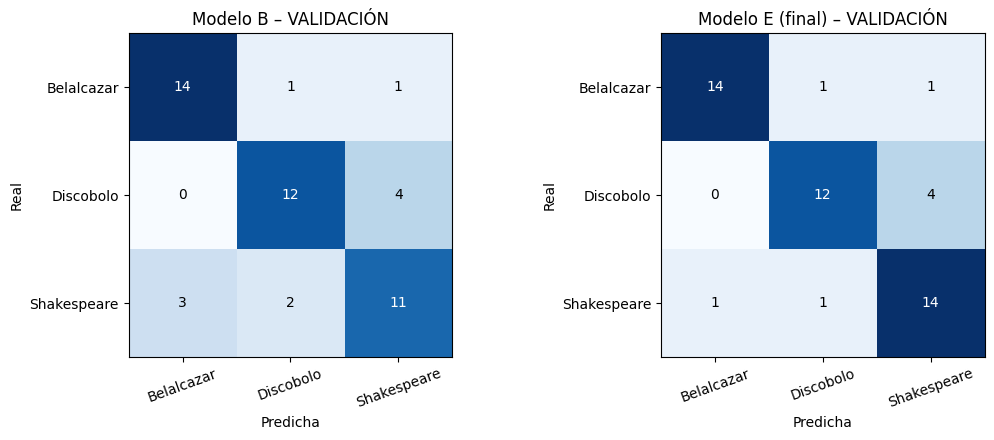

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

@torch.no_grad()
def predict(model, loader):
    model.eval()                                   # apaga Dropout
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (name, m) in zip(ax, [('Modelo B', model_B), ('Modelo E (final)', model_E)]):
    y_true, y_pred = predict(m, loaders['val'])
    cm = confusion_matrix(y_true, y_pred)
    a.imshow(cm, cmap='Blues')
    a.set_xticks(range(3)); a.set_xticklabels(CLASSES, rotation=20)
    a.set_yticks(range(3)); a.set_yticklabels(CLASSES)
    a.set_xlabel('Predicha'); a.set_ylabel('Real'); a.set_title(f'{name} – VALIDACIÓN')
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha='center', va='center',
                   color='white' if cm[i, j] > cm.max() / 2 else 'black')
    print(f"--- {name} (validación) ---")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))
plt.tight_layout(); plt.show()

#Análisis de la matriz de confusión (conjunto de validación)

| Modelo E | Precision | Recall | F1 |
|---|---|---|---|
| Belalcazar | 0.933 | 0.875 | 0.903 |
| Discobolo | 0.857 | 0.750 | 0.800 |
| Shakespeare | 0.737 | 0.875 | 0.800 |
| **Accuracy global** | | | **0.833 (40 de 48)** |

**Lectura global.** E acierta 40 de 48 fotos. Su mejora sobre B (77.1 %, 37 de 48) viene de una sola clase: las filas de Belalcazar (14/1/1) y Discobolo (0/12/4) son idénticas en ambos modelos, y solo cambia Shakespeare (B acierta 11 de 16 y E acierta 14 de 16).

**Lectura por clase.**
- **Belalcazar** es la más estable: un solo error hacia cada una de las otras clases.
- **Discobolo** tiene el recall más bajo (0.750): 4 de sus 16 fotos se predicen como Shakespeare, y ese error no desaparece al pasar de B a E.
- **Shakespeare** tiene el mayor recall junto a Belalcazar (0.875) pero la precision más baja (0.737), porque absorbe las 4 fotos de Discobolo mal clasificadas: de 19 fotos que E llama Shakespeare, 14 lo son.

**Los errores se agrupan por persona/escena.** Las 8 fotos falladas corresponden a solo 4 personas o escenas, con 2 fotos casi gemelas cada una: dos de Belalcazar (misma persona con sudadera, mismo salón), dos de Discobolo (persona con camiseta negra y gorra), otras dos de Discobolo (persona con camiseta blanca y cortinas) y dos de Shakespeare (misma persona de noche, frente a una pared de ladrillo). En dos de esos grupos las dos fotos se confunden con la **misma** clase equivocada (Discobolo → Shakespeare) y en los otros dos con clases distintas. Es decir, el error no está repartido al azar: depende de quién aparece y en qué entorno.

**Posible explicación (hipótesis, no demostrada).** Con pocas personas y fondos en train, la red puede apoyarse en rasgos de la persona o del entorno además de la pose, y falla cuando aparece una persona o un fondo nuevo. Esto es coherente con la agrupación de errores y con que la augmentation de color ayudara, pero no se probó directamente (por ejemplo con Grad-CAM o recortando a la persona). Otras explicaciones posibles son poses poco marcadas en esas fotos concretas o simple ruido.

**Cuidado con las cifras.** Como los errores vienen en pares casi idénticos, las 48 fotos de validación equivalen a menos de 48 muestras independientes, y cada persona mal clasificada mueve el accuracy en saltos de al menos 2 fotos (4.2 puntos). Además, esta validación se usó para elegir el modelo, así que estas métricas son optimistas.

Fotos de validación mal clasificadas por E: 8 de 48


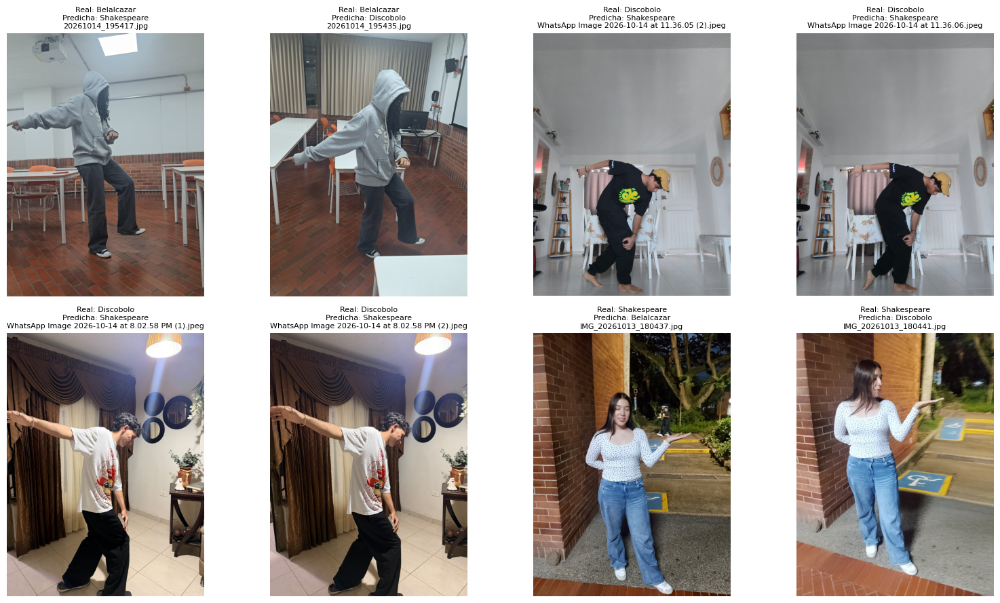

In [ ]:
y_true, y_pred = predict(model_E, loaders['val'])      # loader de val sin barajar: mismo orden que data['val']
wrong = np.where(y_true != y_pred)[0]
print(f"Fotos de validación mal clasificadas por E: {len(wrong)} de {len(y_true)}")

fig, ax = plt.subplots(2, 4, figsize=(16, 9))
for a, k in zip(ax.flat, wrong):
    p = data['val'][2][k]
    a.imshow(ImageOps.exif_transpose(Image.open(p)))      # foto original, no la de 128x128
    a.set_title(f"Real: {CLASSES[y_true[k]]}\nPredicha: {CLASSES[y_pred[k]]}\n{p.name}", fontsize=8)
    a.axis('off')
for a in ax.flat[len(wrong):]: a.axis('off')
plt.tight_layout(); plt.show()

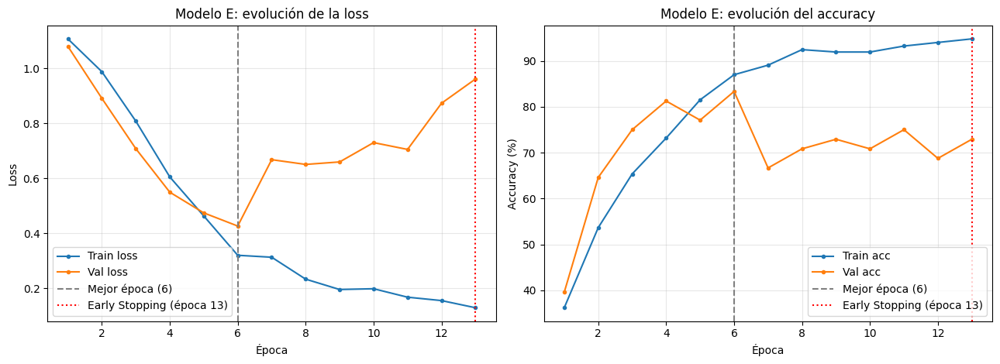

Mejor época: 6 | train loss 0.3199 | val loss 0.4263 | val acc 83.3%
Última época (13): train loss 0.1291 | val loss 0.9613 | val acc 72.9%
Brecha val-train en la mejor época: 0.1064 | en la última: 0.8322


In [ ]:
h = hist_E
ep = range(1, len(h['train_loss']) + 1)
best, last = h['best_epoch'], len(h['train_loss'])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Loss de train y validación
ax[0].plot(ep, h['train_loss'], marker='o', ms=3, label='Train loss')
ax[0].plot(ep, h['val_loss'],   marker='o', ms=3, label='Val loss')
ax[0].axvline(best, ls='--', color='gray', label=f'Mejor época ({best})')
ax[0].axvline(last, ls=':',  color='red',  label=f'Early Stopping (época {last})')
ax[0].set_title('Modelo E: evolución de la loss'); ax[0].set_xlabel('Época'); ax[0].set_ylabel('Loss')
ax[0].legend(); ax[0].grid(alpha=0.3)

# Accuracy de train y validación
ax[1].plot(ep, h['train_acc'], marker='o', ms=3, label='Train acc')
ax[1].plot(ep, h['val_acc'],   marker='o', ms=3, label='Val acc')
ax[1].axvline(best, ls='--', color='gray', label=f'Mejor época ({best})')
ax[1].axvline(last, ls=':',  color='red',  label=f'Early Stopping (época {last})')
ax[1].set_title('Modelo E: evolución del accuracy'); ax[1].set_xlabel('Época'); ax[1].set_ylabel('Accuracy (%)')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

b = best - 1
print(f"Mejor época: {best} | train loss {h['train_loss'][b]:.4f} | val loss {h['val_loss'][b]:.4f} | val acc {h['val_acc'][b]:.1f}%")
print(f"Última época ({last}): train loss {h['train_loss'][-1]:.4f} | val loss {h['val_loss'][-1]:.4f} | val acc {h['val_acc'][-1]:.1f}%")
print(f"Brecha val-train en la mejor época: {h['val_loss'][b] - h['train_loss'][b]:.4f} | en la última: {h['val_loss'][-1] - h['train_loss'][-1]:.4f}")

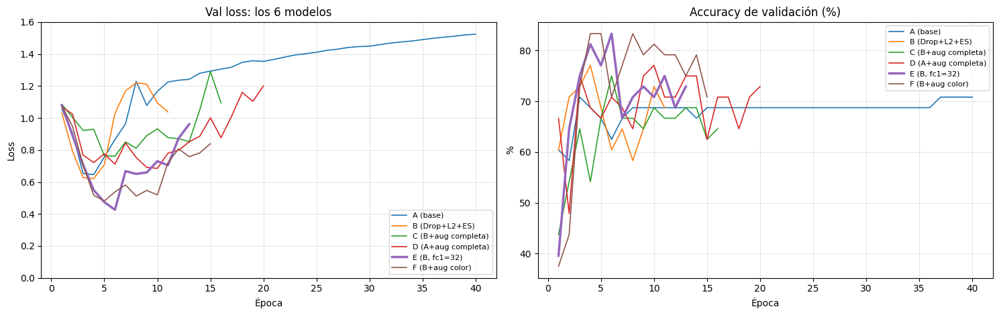

Modelo               Épocas Mejor ép. Train loss*  Val loss*  Val acc*
A (base)                 40         4      0.3411     0.6463     68.8%
B (Drop+L2+ES)           11         4      0.3805     0.6215     77.1%
C (B+aug completa)       16         6      0.6135     0.7613     75.0%
D (A+aug completa)       20        10      0.3180     0.6851     77.1%
E (B, fc1=32)            13         6      0.3199     0.4263     83.3%
F (B+aug color)          15         5      0.3672     0.4809     83.3%
* en la mejor época. La train loss de B, C, E y F se mide con Dropout activo (está inflada).


In [ ]:
hists = {'A (base)': hist_A, 'B (Drop+L2+ES)': hist_B, 'C (B+aug completa)': hist_C,
         'D (A+aug completa)': hist_D, 'E (B, fc1=32)': hist_E, 'F (B+aug color)': hist_F}

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for name, hh in hists.items():
    ax[0].plot(range(1, len(hh['val_loss']) + 1), hh['val_loss'], label=name, lw=2.5 if name.startswith('E') else 1.2)
    ax[1].plot(range(1, len(hh['val_acc']) + 1),  hh['val_acc'],  label=name, lw=2.5 if name.startswith('E') else 1.2)
ax[0].set_title('Val loss: los 6 modelos'); ax[0].set_ylabel('Loss'); ax[0].set_ylim(0, 1.6)
ax[1].set_title('Accuracy de validación (%)'); ax[1].set_ylabel('%')
for a in ax: a.set_xlabel('Época'); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'Modelo':20s} {'Épocas':>6s} {'Mejor ép.':>9s} {'Train loss*':>11s} {'Val loss*':>10s} {'Val acc*':>9s}")
for name, hh in hists.items():
    b = hh['best_epoch'] - 1
    print(f"{name:20s} {len(hh['val_loss']):6d} {hh['best_epoch']:9d} "
          f"{hh['train_loss'][b]:11.4f} {hh['val_loss'][b]:10.4f} {hh['val_acc'][b]:8.1f}%")
print("* en la mejor época. La train loss de B, C, E y F se mide con Dropout activo (está inflada).")

#Regularización

Técnicas aplicadas en el modelo final (E): **Early Stopping, Dropout (0.5 en `fc1`) y L2 (`weight_decay=1e-4`)**. Además se probaron Data Augmentation y una reducción de capacidad. Todas las cifras son la mejor época por val loss.

| Modelo | Cambio | Val loss | Época | Val acc |
|---|---|---|---|---|
| A | base, sin regularizar | 0.6463 | 4 | 68.8 % |
| B | Dropout + L2 + ES | 0.6215 | 4 | 77.1 % |
| C | B + augmentation completa | 0.7613 | 6 | 75.0 % |
| D | A + augmentation completa + ES | 0.6851 | 10 | 77.1 % |
| **E** | **B con `fc1`=32** | **0.4263** | 6 | 83.3 % |
| F | B + augmentation solo de color | 0.4809 | 5 | 83.3 % |

- **Early Stopping (patience 7, restaura los mejores pesos).** Resulta adecuado porque la val loss toca su mínimo pronto (época 4 a 6) y luego sube. Su aporte es el más claro: A, sin él, termina con val loss 1.5238 (2.4 veces su mínimo), mientras que B se detuvo en la época 11 y recuperó los pesos de la época 4 (0.6215) en vez de quedarse con 1.0374. Limitación: usa la validación para decidir, lo que la hace menos independiente.
- **Dropout 0.5 en `fc1`.** Es adecuado porque `fc1` concentra el 98.9 % de los parámetros de B. Su efecto visible es retrasar la memorización: en la época 11 la train loss de B es 0.0346 y la de A es 0.0018. Pero **no se demostró que mejore la generalización**: la diferencia en el mínimo de val loss es de solo 0.025 y el promedio de val loss entre las épocas 5 y 11 es 1.0670 en B contra 1.0406 en A. La diferencia de accuracy (77.1 % contra 68.8 %) son 4 fotos de 48.
- **L2 (`weight_decay=1e-4`).** Penaliza pesos grandes y se usó junto con Dropout, así que **su efecto individual no se puede aislar** con estos experimentos.
- **Data Augmentation.** La versión completa (recorte, rotación de ±10° y color) **empeoró** el resultado: C (0.7613) contra B (0.6215) y D (0.6851) contra A (0.6463). La versión solo de color (F, 0.4809) **mejoró** a B. C y F usan el mismo patience y difieren solo en el tipo de transformación. Una explicación plausible (hipótesis) es que recortar y rotar altera la geometría que define cada pose, mientras que variar brillo y contraste aporta robustez a las condiciones de luz, que en este dataset cambian mucho. El modelo final no usa augmentation.
- **Reducción de capacidad (`fc1` 128 → 32).** Redujo los parámetros de 2,121,251 a 548,003 y fue el cambio con mayor mejora (val loss 0.6215 → 0.4263). Apoya la idea de que había más capacidad que datos.
- **Cómo se eligió el modelo.** Antes de ver los resultados de E y F se fijó que un modelo reemplazaría a B solo si mejoraba su val loss en más de 0.05. Ambos lo cumplieron y se eligió E por tener la menor.

**Veredicto.** La regularización ayudó, pero de forma desigual: Early Stopping y la reducción de capacidad tienen efecto claro; Dropout y L2 retrasan la memorización sin evidencia sólida de mejor generalización; la augmentation depende del tipo. Cada modelo se entrenó una sola vez y la elección entre seis modelos se hizo sobre la misma validación de 48 fotos, por lo que la val loss de E está probablemente algo sobreestimada.

#Análisis del aprendizaje

**Convergencia.** El Modelo E converge en entrenamiento: la train loss baja de forma continua de 1.1072 a 0.1291 (época 13). La generalización óptima llega en la **época 6**, con train loss 0.3199, val loss 0.4263 y val accuracy 83.3 %. En las épocas 1 a 6 ambas pérdidas bajan juntas, que es un aprendizaje sano.

Sobreajuste (overfitting): sí presenta. En la época 7 la val loss salta a 0.6677 y después sube hasta 0.9613, mientras la train loss sigue bajando. La brecha val - train pasa de 0.1064 en la mejor época a 0.8322 en la última. Early Stopping cortó en la época 13 (7 épocas sin mejorar) y restauró los pesos de la época 6. El Modelo A muestra lo mismo sin freno: train loss de 0.0001 y accuracy de train de 100 % desde la época 9, con una val loss que sube de 0.6463 a 1.5238 y un accuracy de val que se queda entre 62.5 % y 70.8 %.

Subajuste (underfitting): no La red alcanza 87.0 % de accuracy de train en la mejor época y 94.8 % en la última, así que tiene capacidad suficiente para aprender los datos de entrenamiento.

**Cómo se manifiesta en las métricas.** La loss y el accuracy cuentan historias distintas: en E el accuracy de validación de la época 13 (72.9 %) es parecido al de épocas anteriores, pero la val loss es mucho mayor. La red acierta con menos margen y, cuando falla, lo hace con mucha confianza (sobreconfianza). Por eso el mínimo de la val loss, y no el accuracy, es el criterio de parada.

**Relación con las decisiones de diseño.**
- Con `fc1`=128, esa capa tenía el 98.9 % de los 2,121,251 parámetros para solo 384 imágenes de entrenamiento: demasiada capacidad para memorizar. Reducirla a 32 bajó la val loss de 0.6215 a 0.4263, pero incluso en E `fc1` conserva el 95.7 % de los parámetros, lo que explica que el sobreajuste persista después de la época 6.
- Dropout y L2 suavizan y retrasan el sobreajuste, pero no lo eliminan: la brecha igual se abre.
- Las 8 fotos falladas en validación vienen de 4 personas o escenas distintas. Si la red se apoya parcialmente en la persona o el fondo, memorizar train es fácil y generalizar a personas nuevas es difícil, lo que sería coherente con la forma de las curvas. Esta relación es una hipótesis.

**Limitaciones del análisis.** Validación de 48 fotos (con fotos casi gemelas) y validación usada tanto para parar el entrenamiento como para elegir entre seis modelos. Los saltos de la val loss (por ejemplo 0.4263 → 0.6677) son en parte ruido.

#YOLO (You only Look Once)

#### Paso a paso del proceso de detección:
1. **División en Rejilla:** YOLO divide la imagen en una cuadrícula o rejilla *(grid, una matriz de celdas imaginarias de $S \times S$)*.
2. **Asignación de Responsabilidad:** Si el centro de un objeto cae dentro de una celda específica, esa celda se vuelve la "responsable" de predecir dicho objeto.
3. **Predicción Simultánea:** Cada celda predice al mismo tiempo:
   * **Bounding Box *(cuadro delimitador, el recuadro que encierra al objeto)*:** Sus coordenadas del centro $(b_x, b_y)$, ancho $(b_w)$ y alto $(b_h)$.
   * **Confidence Score *(puntuación de confianza, un número entre 0 y 1 que indica qué tan seguro está el modelo de que ahí hay un objeto)*.**
   * **Probabilidades de Clase *(porcentaje de certeza sobre qué tipo de objeto es, como persona, carro o silla)*.**

---

### Componentes de la Arquitectura de YOLO

La estructura interna de las versiones modernas de YOLO (como YOLOv8 o YOLO11) se divide en tres partes principales:

1. **Backbone *(dorsal o columna vertebral de la red)*:** Es la primera etapa de la red neuronal compuesta por capas convolucionales *(filtros matemáticos que extraen características visuales como bordes, colores, texturas y formas)*. Su función es convertir la imagen cruda en un mapa de características *(una representación abstracta con la información más importante de la foto)*.
2. **Neck *(cuello de la red)*:** Es una etapa intermedia que combina información de diferentes capas. Permite mezclar características de baja resolución *(detalles generales de la escena)* con características de alta resolución *(detalles finos de objetos pequeños)*. Esto ayuda a que el modelo detecte tanto objetos gigantes como muy pequeños.
3. **Head *(cabeza predictora)*:** Es la última etapa de la red. Toma el mapa de características procesado y genera las predicciones finales: los recuadros delimitadores y las etiquetas de los objetos.

#### Algoritmos de Post-Procesamiento (Limpieza de resultados):
* **IoU *(Intersection over Union o Intersección sobre la Unión)*:** Es una fórmula matemática que mide el grado de superposición entre la caja predicha por el modelo y la posición real del objeto. Si el resultado es cercano a 1, la predicción es casi perfecta.
* **NMS *(Non-Maximum Suppression o Supresión No Máxima)*:** Debido a que varias celdas adyacentes pueden detectar el mismo objeto y generar múltiples cajas encimadas, NMS es un filtro de limpieza que elimina los recuadros duplicados o redundantes y conserva únicamente la caja con la mayor puntuación de confianza.

---

## 2. Comparativa con otros Modelos Modernos de Detección

Existen otros enfoques en la literatura de inteligencia artificial para resolver la detección de objetos. A continuación se detallan las diferencias clave entre YOLO y sus principales competidores:

| Modelo / Familia | Enfoque de Funcionamiento | Ventajas Principales | Desventajas frente a YOLO |
| :--- | :--- | :--- | :--- |
| **YOLO** *(You Only Look Once)* | **Una sola etapa *(One-Stage)*:** Analiza la imagen completa y predice cajas y clases simultáneamente. | Extremadamente rápido, ideal para tiempo real *(procesamiento en vivo)* y dispositivos con recursos limitados. | Falla en detectar objetos muy pequeños o apelotonados si la resolución es baja. |
| **Faster R-CNN** *(Region-based Convolutional Neural Network)* | **Dos etapas *(Two-Stage)*:** Primero propone regiones donde podría haber objetos *(RPN, Region Proposal Network)* y luego clasifica cada región. | Mayor precisión en objetos pequeños, escenas complejas o con mucha oclusión *(objetos tapados por otros)*. | Es muy lento. No es apto para tiempo real en video fluido sin GPUs *(unidades de procesamiento gráfico de alto rendimiento)* costosas. |
| **SSD** *(Single Shot MultiBox Detector)* | **Una sola etapa *(One-Stage)*:** Similar a YOLO, utiliza mapas de características de múltiples escalas para predecir cajas. | Rápido y con buen desempeño en objetos de variados tamaños. | Tiende a ser menos preciso que las versiones recientes de YOLO y requiere más ajustes manuales. |
| **RT-DETR** *(Real-Time Detection Transformer)* | **Basado en Transformers *(Atención Visual)*:** Utiliza mecanismos de auto-atención *(algoritmo que evalúa cómo se relacionan las partes de la imagen entre sí)* sin usar NMS. | Alta precisión global, entiende el contexto de la escena sin requerir algoritmos de limpieza post-procesamiento. | Requiere mayor capacidad de cómputo en la fase de entrenamiento y consumo de memoria elevado. |

---

## 3. Implementación Práctica en los Sótanos de la UAO

Para verificar el funcionamiento del modelo en un entorno real, se utilizó la librería `ultralytics` *(herramienta oficial en Python para ejecutar modelos YOLO)* y se procesó un conjunto de imágenes capturadas en las instalaciones de los sótanos de la Universidad Autónoma de Occidente (UAO).



In [ ]:
%pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 549.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 4.4 MB/s eta 0:00:00


Se encontraron 13 imágenes para procesar.

=== IMG1.jpg ===
Total de objetos detectados: 35

Resumen por clase:
   • chair: 28 (promedio 0.57 | mín 0.26 | máx 0.90)
   • person: 4 (promedio 0.38 | mín 0.33 | máx 0.50)
   • dining table: 3 (promedio 0.39 | mín 0.26 | máx 0.59)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.90
    2. chair           0.90
    3. chair           0.88
    4. chair           0.87
    5. chair           0.81
    6. chair           0.81
    7. chair           0.79
    8. chair           0.78
    9. chair           0.71
   10. chair           0.70
   11. chair           0.67
   12. chair           0.64
   13. chair           0.61
   14. chair           0.60
   15. dining table    0.59
   16. chair           0.59
   17. chair           0.51
   18. person          0.50
   19. chair           0.47
   20. chair           0.45
   21. chair           0.42
   22. person          0.36
   23. chair           0.36
   24. chair           0.

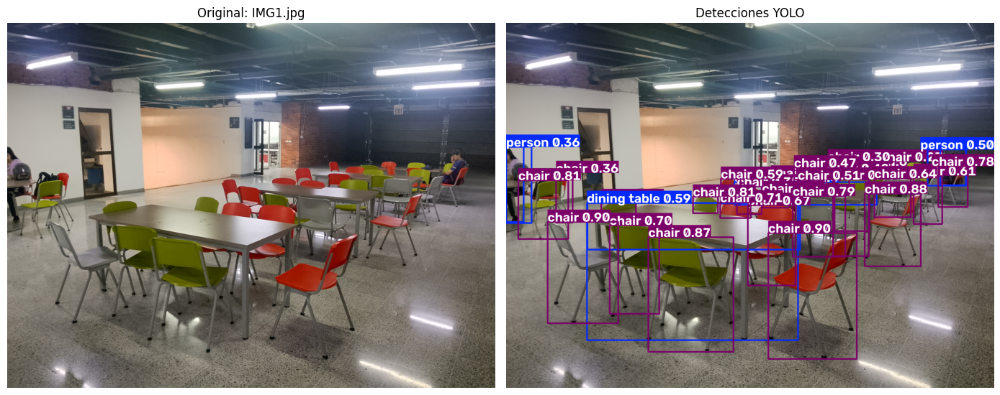



=== IMG10.jpg ===
Total de objetos detectados: 33

Resumen por clase:
   • chair: 16 (promedio 0.50 | mín 0.26 | máx 0.79)
   • person: 11 (promedio 0.48 | mín 0.31 | máx 0.67)
   • dining table: 4 (promedio 0.52 | mín 0.42 | máx 0.62)
   • laptop: 1 (promedio 0.86 | mín 0.86 | máx 0.86)
   • backpack: 1 (promedio 0.30 | mín 0.30 | máx 0.30)

Detalle de cada detección (mayor a menor confianza):
    1. laptop          0.86
    2. chair           0.79
    3. chair           0.79
    4. person          0.67
    5. chair           0.67
    6. chair           0.66
    7. person          0.65
    8. chair           0.64
    9. dining table    0.62
   10. person          0.62
   11. dining table    0.60
   12. person          0.57
   13. chair           0.54
   14. chair           0.53
   15. chair           0.53
   16. person          0.47
   17. person          0.46
   18. person          0.44
   19. dining table    0.44
   20. chair           0.44
   21. dining table    0.42
   22. chair

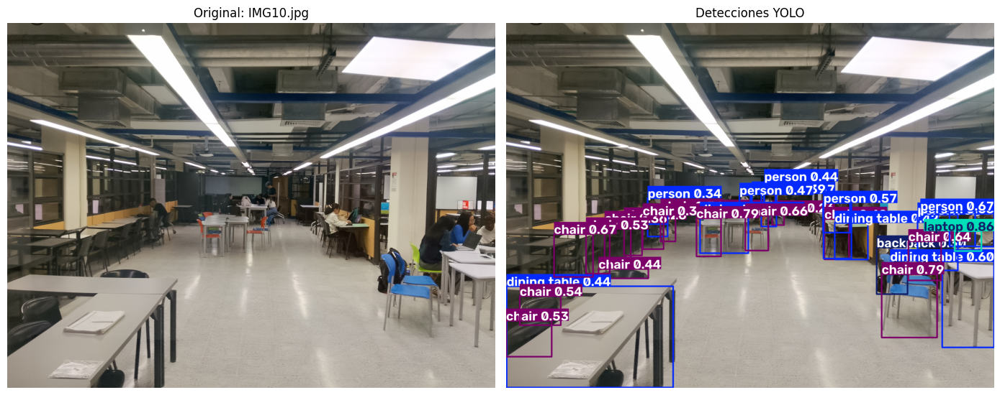



=== IMG11.jpg ===
Total de objetos detectados: 7

Resumen por clase:
   • person: 3 (promedio 0.54 | mín 0.28 | máx 0.82)
   • tv: 2 (promedio 0.31 | mín 0.27 | máx 0.36)
   • laptop: 1 (promedio 0.62 | mín 0.62 | máx 0.62)
   • chair: 1 (promedio 0.29 | mín 0.29 | máx 0.29)

Detalle de cada detección (mayor a menor confianza):
    1. person          0.82
    2. laptop          0.62
    3. person          0.51
    4. tv              0.36
    5. chair           0.29
    6. person          0.28
    7. tv              0.27


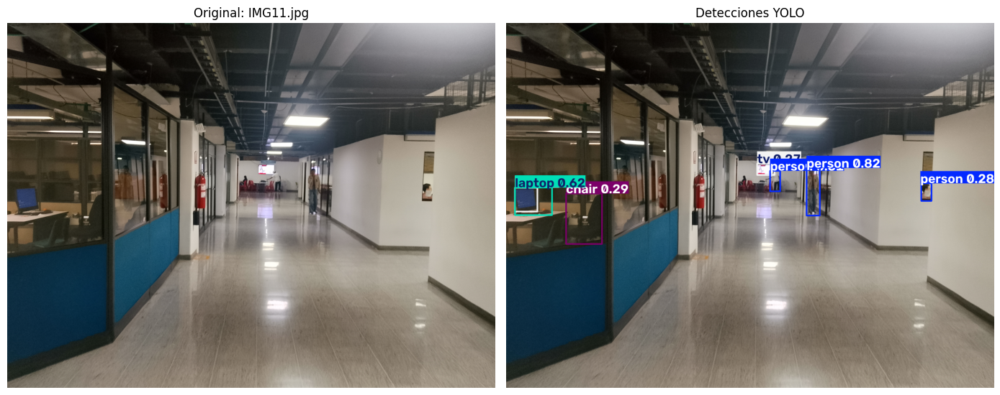



=== IMG2.jpg ===
Total de objetos detectados: 27

Resumen por clase:
   • chair: 15 (promedio 0.52 | mín 0.26 | máx 0.87)
   • person: 6 (promedio 0.44 | mín 0.29 | máx 0.85)
   • dining table: 4 (promedio 0.40 | mín 0.26 | máx 0.61)
   • laptop: 1 (promedio 0.69 | mín 0.69 | máx 0.69)
   • tv: 1 (promedio 0.43 | mín 0.43 | máx 0.43)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.87
    2. person          0.85
    3. chair           0.80
    4. chair           0.72
    5. chair           0.70
    6. laptop          0.69
    7. chair           0.68
    8. dining table    0.61
    9. chair           0.56
   10. chair           0.55
   11. chair           0.54
   12. chair           0.53
   13. person          0.43
   14. tv              0.43
   15. dining table    0.43
   16. chair           0.42
   17. person          0.41
   18. person          0.37
   19. chair           0.35
   20. chair           0.31
   21. person          0.31
   22. dining table 

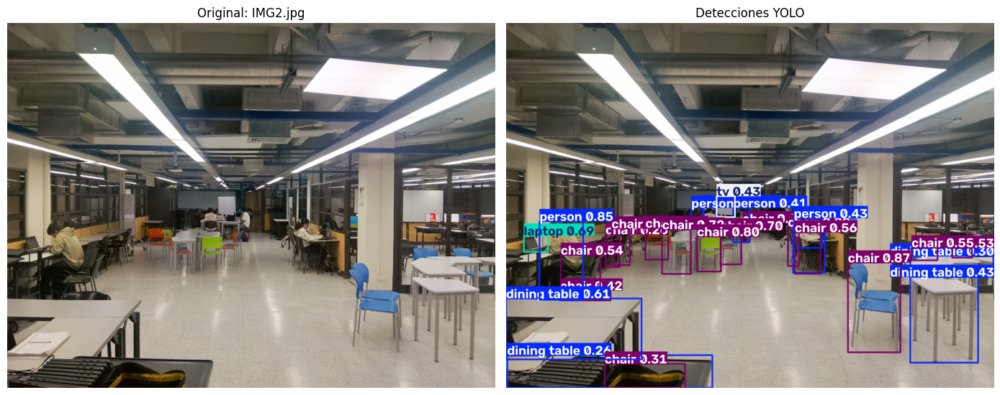



=== IMG3.jpg ===
Total de objetos detectados: 13

Resumen por clase:
   • chair: 6 (promedio 0.75 | mín 0.57 | máx 0.82)
   • person: 2 (promedio 0.57 | mín 0.30 | máx 0.83)
   • refrigerator: 2 (promedio 0.49 | mín 0.31 | máx 0.66)
   • dining table: 2 (promedio 0.39 | mín 0.38 | máx 0.39)
   • tv: 1 (promedio 0.64 | mín 0.64 | máx 0.64)

Detalle de cada detección (mayor a menor confianza):
    1. person          0.83
    2. chair           0.82
    3. chair           0.81
    4. chair           0.79
    5. chair           0.78
    6. chair           0.72
    7. refrigerator    0.66
    8. tv              0.64
    9. chair           0.57
   10. dining table    0.39
   11. dining table    0.38
   12. refrigerator    0.31
   13. person          0.30


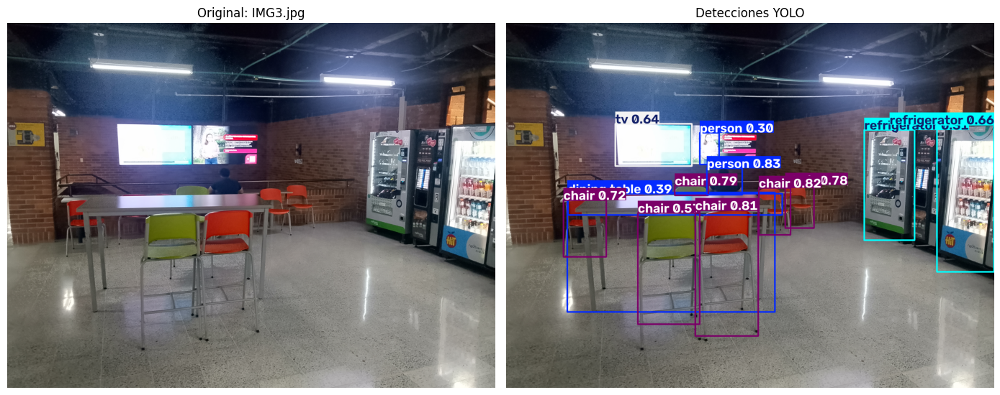



=== IMG4.jpg ===
Total de objetos detectados: 13

Resumen por clase:
   • chair: 5 (promedio 0.67 | mín 0.29 | máx 0.93)
   • dining table: 3 (promedio 0.49 | mín 0.38 | máx 0.66)
   • person: 2 (promedio 0.73 | mín 0.57 | máx 0.88)
   • handbag: 2 (promedio 0.31 | mín 0.27 | máx 0.36)
   • couch: 1 (promedio 0.51 | mín 0.51 | máx 0.51)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.93
    2. chair           0.91
    3. person          0.88
    4. chair           0.74
    5. dining table    0.66
    6. person          0.57
    7. couch           0.51
    8. chair           0.49
    9. dining table    0.44
   10. dining table    0.38
   11. handbag         0.36
   12. chair           0.29
   13. handbag         0.27


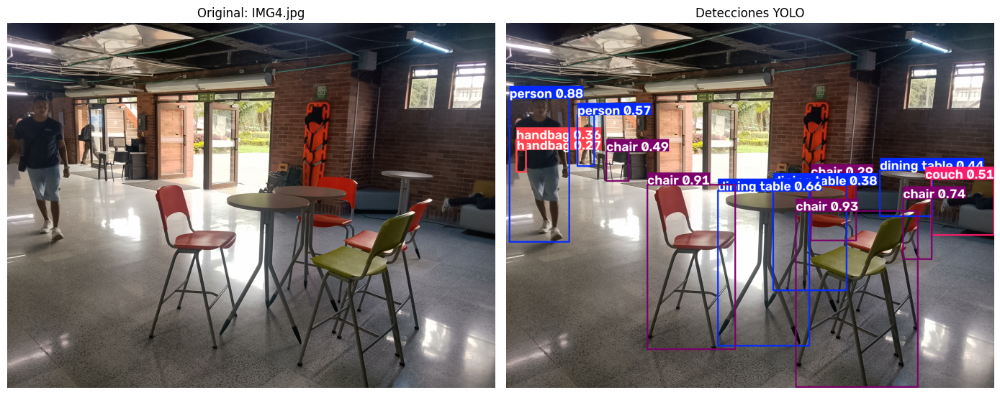



=== IMG5.jpg ===
Total de objetos detectados: 3

Resumen por clase:
   • oven: 1 (promedio 0.37 | mín 0.37 | máx 0.37)
   • chair: 1 (promedio 0.33 | mín 0.33 | máx 0.33)
   • refrigerator: 1 (promedio 0.27 | mín 0.27 | máx 0.27)

Detalle de cada detección (mayor a menor confianza):
    1. oven            0.37
    2. chair           0.33
    3. refrigerator    0.27


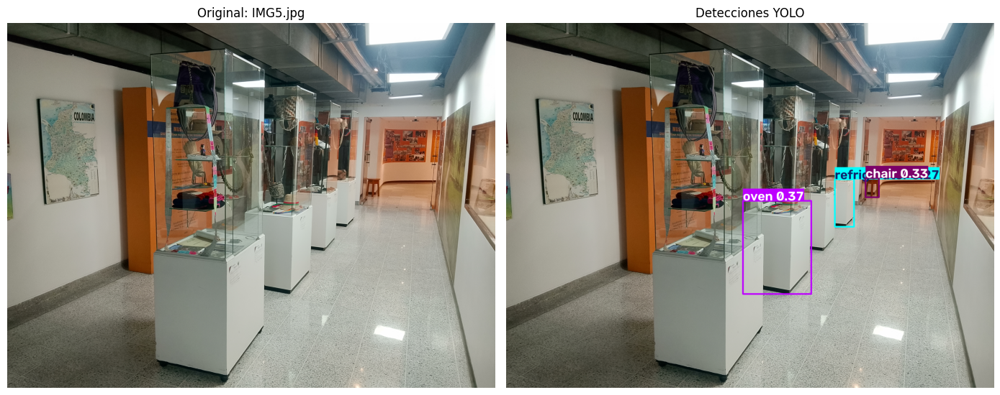



=== IMG6.jpg ===
Total de objetos detectados: 5

Resumen por clase:
   • person: 5 (promedio 0.77 | mín 0.70 | máx 0.84)

Detalle de cada detección (mayor a menor confianza):
    1. person          0.84
    2. person          0.82
    3. person          0.80
    4. person          0.71
    5. person          0.70


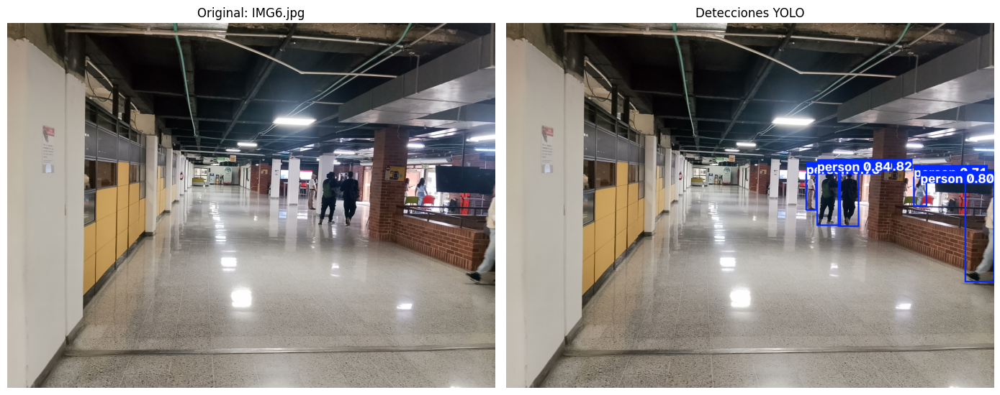



=== IMG7.jpg ===
Total de objetos detectados: 16

Resumen por clase:
   • chair: 14 (promedio 0.63 | mín 0.27 | máx 0.90)
   • dining table: 2 (promedio 0.53 | mín 0.32 | máx 0.73)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.90
    2. chair           0.82
    3. chair           0.78
    4. chair           0.78
    5. chair           0.77
    6. chair           0.76
    7. dining table    0.73
    8. chair           0.69
    9. chair           0.67
   10. chair           0.59
   11. chair           0.54
   12. chair           0.51
   13. chair           0.39
   14. chair           0.37
   15. dining table    0.32
   16. chair           0.27


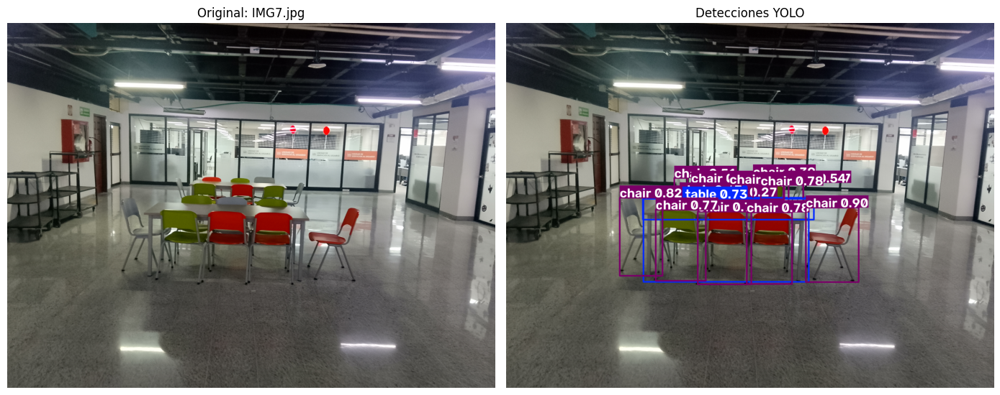



=== IMG8.jpg ===
Total de objetos detectados: 26

Resumen por clase:
   • chair: 19 (promedio 0.61 | mín 0.25 | máx 0.94)
   • dining table: 5 (promedio 0.59 | mín 0.29 | máx 0.85)
   • person: 2 (promedio 0.82 | mín 0.80 | máx 0.83)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.94
    2. chair           0.92
    3. chair           0.91
    4. dining table    0.85
    5. dining table    0.85
    6. chair           0.85
    7. person          0.83
    8. chair           0.81
    9. person          0.80
   10. chair           0.80
   11. chair           0.78
   12. chair           0.70
   13. chair           0.70
   14. dining table    0.69
   15. chair           0.67
   16. chair           0.59
   17. chair           0.51
   18. chair           0.51
   19. chair           0.50
   20. chair           0.34
   21. chair           0.33
   22. dining table    0.29
   23. dining table    0.29
   24. chair           0.29
   25. chair           0.29
   26. cha

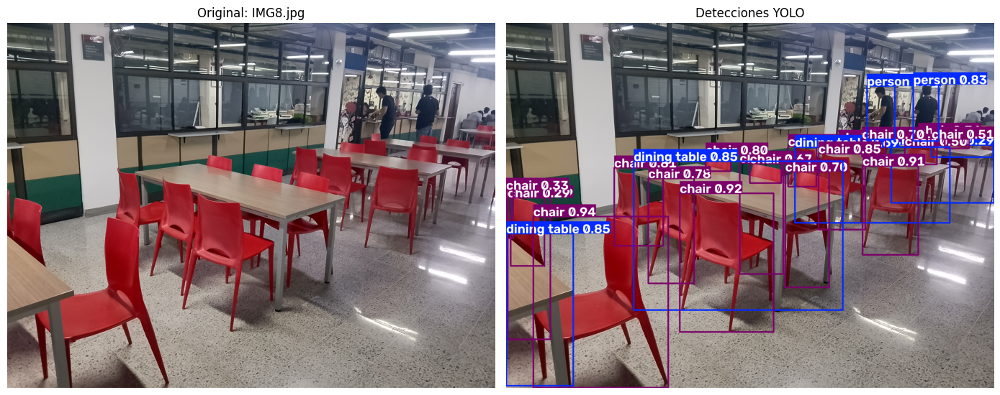



=== IMG9.jpg ===
Total de objetos detectados: 34

Resumen por clase:
   • chair: 30 (promedio 0.55 | mín 0.25 | máx 0.94)
   • dining table: 4 (promedio 0.62 | mín 0.29 | máx 0.82)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.94
    2. chair           0.90
    3. chair           0.88
    4. chair           0.87
    5. chair           0.85
    6. chair           0.83
    7. dining table    0.82
    8. chair           0.80
    9. chair           0.78
   10. chair           0.77
   11. dining table    0.77
   12. chair           0.76
   13. chair           0.76
   14. chair           0.66
   15. dining table    0.59
   16. chair           0.54
   17. chair           0.52
   18. chair           0.50
   19. chair           0.50
   20. chair           0.50
   21. chair           0.50
   22. chair           0.42
   23. chair           0.40
   24. chair           0.35
   25. chair           0.34
   26. chair           0.33
   27. chair           0.31
   28. 

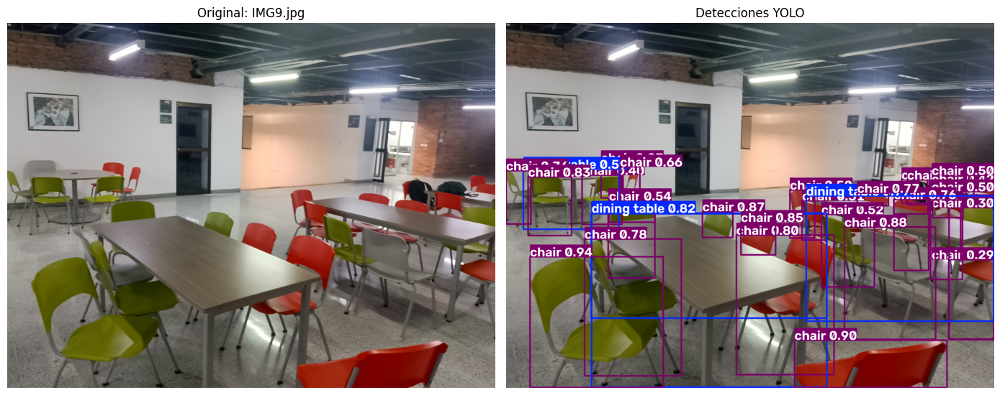



=== IMGBlur.png ===
Total de objetos detectados: 6

Resumen por clase:
   • person: 6 (promedio 0.55 | mín 0.27 | máx 0.85)

Detalle de cada detección (mayor a menor confianza):
    1. person          0.85
    2. person          0.69
    3. person          0.56
    4. person          0.51
    5. person          0.41
    6. person          0.27


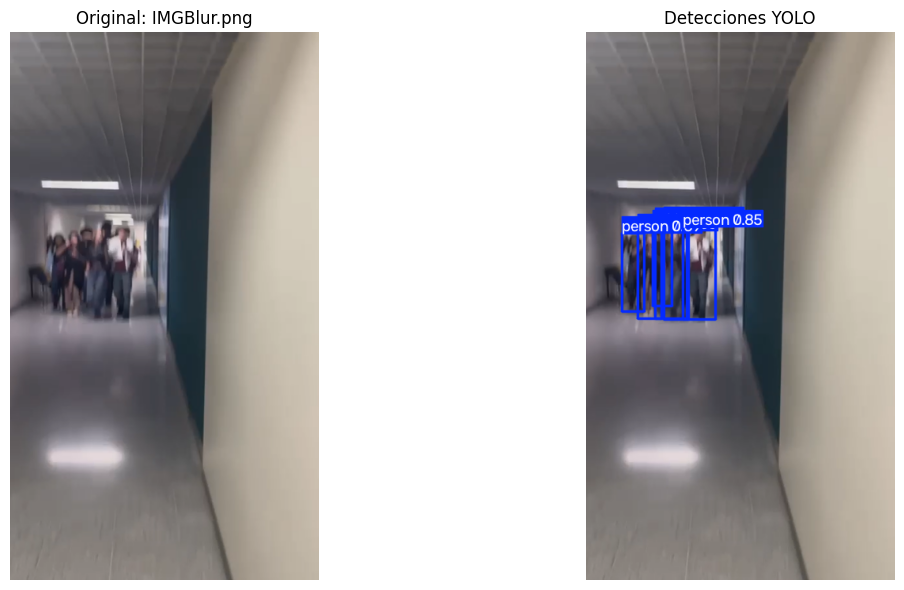



=== IMGOscura.jpg ===
Total de objetos detectados: 16

Resumen por clase:
   • chair: 9 (promedio 0.55 | mín 0.28 | máx 0.88)
   • dining table: 4 (promedio 0.41 | mín 0.28 | máx 0.62)
   • tv: 2 (promedio 0.61 | mín 0.48 | máx 0.75)
   • clock: 1 (promedio 0.75 | mín 0.75 | máx 0.75)

Detalle de cada detección (mayor a menor confianza):
    1. chair           0.88
    2. chair           0.79
    3. chair           0.78
    4. tv              0.75
    5. clock           0.75
    6. chair           0.67
    7. dining table    0.62
    8. chair           0.59
    9. tv              0.48
   10. dining table    0.40
   11. chair           0.37
   12. dining table    0.34
   13. chair           0.28
   14. chair           0.28
   15. chair           0.28
   16. dining table    0.28


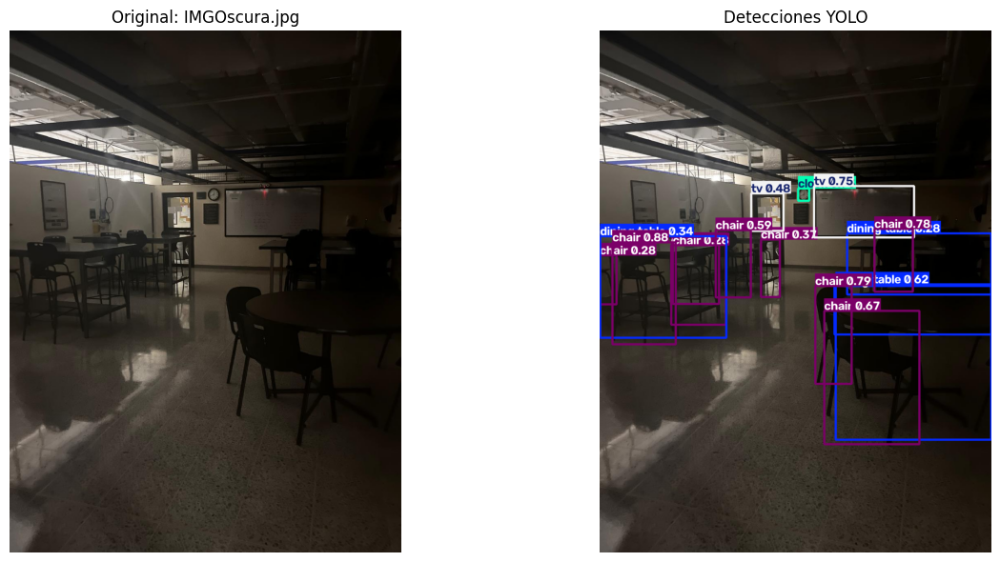

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from collections import defaultdict
from ultralytics import YOLO

# 1. Cargar el modelo YOLO
model = YOLO("yolo11m.pt")

# 2. Definir la ruta de la carpeta
folder_path = "/content/drive/MyDrive/PDI - Parcial2/Yolo"

# Extensiones válidas de imágenes
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.JPG', '.JPEG', '.PNG')

# Obtener y ordenar la lista de imágenes
image_names = [f for f in os.listdir(folder_path) if f.endswith(valid_extensions)]
image_names.sort()

print(f"Se encontraron {len(image_names)} imágenes para procesar.\n")

# 3. Recorrer cada imagen
for img_name in image_names:
    img_path = os.path.join(folder_path, img_name)

    # A. Cargar imagen original
    orig_bgr = cv2.imread(img_path)
    if orig_bgr is None:
        continue
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)

    # B. Ejecutar la detección con YOLO
    results = model(img_path, verbose=False)

    # C. Extraer clase y confianza de cada detección
    boxes = results[0].boxes
    detecciones = []  # lista de (nombre_clase, confianza)
    if len(boxes) > 0:
        class_ids = boxes.cls.int().cpu().tolist()
        confidences = boxes.conf.cpu().tolist()
        detecciones = [(model.names[cid], conf)
                       for cid, conf in zip(class_ids, confidences)]

    # D. Imprimir resultados en texto
    print(f"=== {img_name} ===")
    if detecciones:
        print(f"Total de objetos detectados: {len(detecciones)}\n")

        # D1. Resumen por clase (cantidad, confianza promedio, mínima y máxima)
        por_clase = defaultdict(list)
        for nombre, conf in detecciones:
            por_clase[nombre].append(conf)

        print("Resumen por clase:")
        for nombre, confs in sorted(por_clase.items(), key=lambda x: -len(x[1])):
            print(f"   • {nombre}: {len(confs)} "
                  f"(promedio {sum(confs)/len(confs):.2f} | "
                  f"mín {min(confs):.2f} | máx {max(confs):.2f})")

        # D2. Detalle de cada detección, de mayor a menor confianza
        print("\nDetalle de cada detección (mayor a menor confianza):")
        for i, (nombre, conf) in enumerate(
                sorted(detecciones, key=lambda x: -x[1]), start=1):
            print(f"   {i:>2}. {nombre:<15} {conf:.2f}")
    else:
        print("No se detectaron objetos en esta imagen.")

    # E. Visualizar las imágenes lado a lado
    annotated_bgr = results[0].plot()
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(orig_rgb)
    axes[0].set_title(f"Original: {img_name}")
    axes[0].axis('off')

    axes[1].imshow(annotated_rgb)
    axes[1].set_title("Detecciones YOLO")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
    print("\n")  # Espacio entre iteraciones

## 4. Análisis de Desempeño: ¿Cuándo funciona bien YOLO?

Para evaluar el modelo se revisó cada imagen buscando dos cosas: **qué tan seguro estaba el modelo** y **si lo que detectó coincide con lo que realmente hay en la escena**. Se usó el modelo `yolo11m.pt` *(YOLO11 versión "medium", un equilibrio entre velocidad y precisión)* con el umbral de confianza por defecto de 0.25 *(el valor mínimo de seguridad que debe tener una detección para mostrarse; las que tienen menos se descartan)*.

### 4.1 Condiciones en las que YOLO detecta correctamente

| Condición favorable | ¿Por qué ayuda? *(explicación)* | Ejemplos en las imágenes |
| :--- | :--- | :--- |
| **Iluminación uniforme y suficiente** | Con buena luz los bordes y colores del objeto se ven nítidos, y las capas convolucionales *(filtros que buscan bordes y formas)* extraen características claras. | IMG8, IMG7, IMG9 y IMG2: luz blanca pareja del techo, sin zonas muy oscuras. |
| **Objetos grandes, completos y cercanos** | Un objeto que ocupa muchos píxeles deja mucha información para la red. Si se ve entero, es más fácil reconocer su forma. | IMG8: sillas rojas con confianza de **0.92 a 0.94** y mesas con **0.85**. IMG4: sillas con **0.91 y 0.93** y una persona con **0.88**. |
| **Espacios despejados, con poco desorden** | Si los objetos no se tapan entre sí *(oclusión)*, cada uno tiene su propia caja bien definida y NMS *(el filtro que elimina cajas repetidas)* funciona bien. | IMG7: grupo de sillas con una mesa sobre un fondo limpio, con sillas de **0.77 a 0.90** y mesa de **0.73**. |
| **Personas en pasillos abiertos** | Una persona de cuerpo completo, sobre un fondo liso, tiene una silueta muy reconocible *(la clase "person" es la más representada en el dataset de entrenamiento)*. | IMG6: personas caminando a distancia con **0.80 a 0.84**, incluso una cortada por el borde derecho de la imagen. |
| **Objetos que existen en el dataset COCO** | El modelo fue entrenado con COCO *(un conjunto de millones de imágenes con 80 clases como persona, silla, laptop, tv)*. Solo puede reconocer bien lo que aprendió. | IMG10: laptop con **0.86** y una mochila azul. IMG2: laptop con **0.69**. IMG3: pantalla de TV con **0.64**. |
| **Vista frontal o diagonal suave** | Cuando el objeto se ve desde un ángulo "típico", se parece más a las fotos con las que se entrenó el modelo. | IMG3: sillas altas con **0.81 y 0.82**. IMG4: la mesa con **0.66**. |

**Conclusión de esta parte:** YOLO funciona mejor cuando la escena está bien iluminada, los objetos son grandes y completos, y hay pocas cosas tapándose entre sí. Esto coincide con lo esperado de un modelo de una sola etapa *(One-Stage, que analiza la imagen completa de una sola vez)*: es rápido y preciso en escenas "limpias".

---

## 5. Limitaciones y Errores del Modelo en los Sótanos

### 5.1 Baja iluminación (imagen `IMGOscura.jpeg`)

En la foto con poca luz, YOLO **sigue detectando bastantes objetos**, pero con menos seguridad y con cajas menos precisas:

* Algunas sillas se detectan bien (**0.88, 0.79, 0.78, 0.67**), pero otras quedan con confianza muy baja (**0.28 a 0.37**).
* Las cajas de las mesas (`dining table`) salen **muy grandes y sueltas**, porque los bordes oscuros se confunden con el fondo y con el piso.
* El **tablero blanco de la pared se clasificó como `tv` (0.75)**, es probable que sea porque la zona iluminada de la pared se parece a una pantalla encendida.

**Explicación:** con poca luz hay menos contraste así que los bordes se pierden y las sillas oscuras se mezclan con el piso y las sombras. Las capas convolucionales encuentran menos características útiles, y por eso baja la confianza.

### 5.2 Oclusión y aglomeración de objetos (IMG1, IMG9, IMG10)

La **oclusión** *(cuando un objeto tapa parcialmente a otro)* y la **aglomeración** *(muchos objetos pegados)* son el principal problema:

* En IMG1 se detectaron **28 sillas** cuando realmente hay 34, y en IMG9, **30** cuando realmente hay 26. Hay muchas cajas encimadas con confianza baja (**0.3 a 0.5**). por lo que se presentan ambas caras de la moneda:
  - No se detectan la totalidad de objetos que realmente hay en la imagen
  - No se eliminan correctamente las bounding boxes sobrepuestas (IoU + NMS)
* Las cajas de `dining table` *(mesas)* son enormes y abarcan también las sillas que están alrededor.

**Explicación:** cuando dos sillas se superponen mucho, sus cajas tienen un IoU *(porcentaje de superposición entre dos cajas)* alto. NMS no sabe si son dos sillas distintas o una sola detectada dos veces, y puede conservar duplicados o eliminar una silla real.

### 5.3 Objetos pequeños o lejanos (IMG10, IMG2, IMG11)

* En IMG10 e IMG2, las **personas del fondo** salen con confianza baja (**0.34 a 0.47**), lo que indica detecciones inestables. Es probable que se pierdan otras.
* En IMG11, la persona que se logra ver su cabeza en la ventana de la derecha tiene una confianza de **0.28**, casi en el umbral.

**Explicación:** un objeto lejano ocupa pocos píxeles. Para YOLO, el nivel más fino de detección *(P3, que divide la imagen en celdas de 8×8 píxeles)* casi no recibe información de ese objeto, y la red tiene poco que "ver".

### 5.4 Objetos que no existen en las 80 clases de COCO

YOLO **solo puede nombrar objetos que aprendió**. Cuando ve algo desconocido, no responde "no sé", sino que lo fuerza a la clase más parecida:

| Objeto real | Lo que YOLO detectó | Imagen |
| :--- | :--- | :--- |
| Vitrinas de museo | `oven` (0.37) y `refrigerator` | IMG5 |
| Máquinas expendedoras | `refrigerator` (0.66) | IMG3 |
| Tablero blanco y ventana de la puerta| `tv` (0.75) | IMGOscura |
| Extintor, camilla naranja, carros metálicos | **No detectados** *(no hay clase para ellos)* | IMG11, IMG4, IMG7 |


### 5.5 Falsos positivos por parecido visual

Un **falso positivo** *(cuando el modelo detecta algo que en realidad no está)* aparece cuando un objeto se parece a una clase conocida:

* IMG3: la imagen de una persona en una pantalla se detectó como `person` (**0.30**) - Esto si bien no esta mal, puede llegar a ser un problema en casos de aplicacion real.
* IMG2: un maletin negro en la esquina inferior se detectó como `chair` (**0.31**).

Casi todos tienen **confianza baja**. Esto sugiere que subir el umbral de confianza ayudaría a eliminarlos, a costa de perder algunas detecciones reales.

### 5.6 Espacios reducidos y objetos en movimiento

* **Espacios reducidos:** en pasillos angostos (IMG5, IMG11) los objetos se ven en perspectiva muy inclinada y cortados, lo que dificulta reconocerlos.
* **Objetos en movimiento:** en **IMGBlur** se divisan 6 personas caminando, YOLO fue capaz de detectarlas sin problema, pero solo dos de ellas tienen un valor de confianza alto (0.85 y 0.69)

### 5.7 Resumen de limitaciones

| Problema | Causa técnica | Efecto observado |
| :--- | :--- | :--- |
| Poca luz | Poco contraste, bordes perdidos | Confianza baja y cajas imprecisas |
| Oclusión y aglomeración | IoU alto entre cajas, NMS se confunde | Duplicados y conteos poco confiables |
| Objetos lejanos | Pocos píxeles de información | Confianza baja o sin detección |
| Clases fuera de COCO | El modelo solo conoce 80 clases | Clasificación errónea o sin detección |
| Parecido visual | El modelo generaliza por forma | Falsos positivos de baja confianza |
| Objetos en movimiento | se pierde informacion relevante | Baja confianza al detectar objetos

---

## 6 Conclusiones

* La implementación de YOLO11m **es funcional** en los sótanos de la UAO: detectó personas, sillas, mesas, laptops y pantallas en las 13 imágenes sin necesidad de entrenamiento adicional.
* El desempeño es mejor con luz pareja, objetos grandes y completos, y espacios despejados.
* El desempeño es se ve un poco afectado con poca luz, mucha oclusión, objetos lejanos, vidrios y objetos que no están en COCO.
* **Mejoras posibles:**
  * Usar un modelo más grande (`yolo11l.pt` o `yolo11x.pt`).
  * Aumentar la resolución de las imagenes utilizadas para las pruebas.
  * Ajustar los umbrales de confianza y de IoU.
  * reentrenar parcialmente el modelo con fotos propias para agregar clases como extintores, máquinas expendedoras o tableros.